# 05 — Um dataset astronômico multimodal

Workshop SAB — AI-Scope / ADSS

Vamos cruzar Gaia, DESI e ZTF, reunir os arrays e cutouts S-PLUS em uma tabela e visualizar qualquer fonte por índice. Execute a partir da pasta `notebooks/`.

In [76]:
from io import BytesIO
from pathlib import Path

import adss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

cl = adss.ADSSClient(base_url="https://ai-scope.cbpf.br/")
MAX_OBJECTS = 1000
MATCH_RADIUS_ARCSEC = 1.0

## 1. Escolher uma imagem S-PLUS

`get_collections` lista as coleções de imagens. `cone_search_images` procura arquivos próximos das coordenadas indicadas.

In [77]:
collections = cl.get_collections()
collection_id = next(c["id"] for c in collections if "splus" in c["name"].lower())
files = cl.cone_search_images(collection_id, ra=0, dec=0, radius=2.5,
                              filter_name="R", limit=100)
science = [f for f in files if str(f.get("filter", "")).upper() == "R"
           and "weight" not in f["filename"].lower()
           and f.get("ra_center") is not None and f.get("dec_center") is not None
           and abs((float(f["ra_center"]) + 180) % 360 - 180) <= 2
           and -1 <= float(f["dec_center"]) <= 1]
image_file = min(science, key=lambda f: abs((float(f["ra_center"]) + 180) % 360 - 180)
                 + abs(float(f["dec_center"])))
RA0, DEC0 = float(image_file["ra_center"]), float(image_file["dec_center"])
print(image_file["filename"], RA0, DEC0)

STRIPE82-0001_R_swp.fz 359.99992360541097 -0.699923611110481


## 2. Gaia

Consulte até `MAX_OBJECTS` fontes de `public.gaia_dr3` no polígono RA 358°–2°, Dec −1°–1°. Traga ID, posição, G/BP/RP, paralaxe, movimentos próprios e `ruwe`. Calcule `image_distance_deg` com `dist`, ordene por ela e exija G não nula. Solução: `outputs/respostas.txt`.

In [78]:
gaia_query = f"""
SELECT TOP {MAX_OBJECTS}
    source_id, ra, dec, phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag,
    parallax, pmra, pmdec, ruwe,
    dist(ra, dec, {RA0}, {DEC0}) AS image_distance_deg
FROM public.gaia_dr3
WHERE polygon(ra, dec, 358, -1, 2, -1, 2, 1, 358, 1)
  AND phot_g_mean_mag IS NOT NULL
ORDER BY image_distance_deg
"""
gaia = cl.query_and_wait(query_text=gaia_query, mode="astroql").data
gaia["object_id"] = "gaia_" + gaia["source_id"].astype(str)
objects = gaia[["object_id", "ra", "dec"]]
print(f"Fontes Gaia: {len(gaia)}")
gaia.head()

Check query status at: https://ai-scope.cbpf.br/queries/4e3a9186-0fd2-46c0-af39-216c5e037246
Results fetched.
Fontes Gaia: 1000


,source_id,ra,dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,parallax,pmra,pmdec,ruwe,image_distance_deg,object_id
0,2449850960546191232,0.009517,-0.680439,19.797432,21.076393,18.537184,1.768937,3.027674,-8.816400,1.087202,0.021718,gaia_2449850960546191232
1,2449850479509840896,0.007879,-0.724539,18.737270,19.668087,17.806042,0.538293,11.237408,-3.181053,1.044982,0.025869,gaia_2449850479509840896
2,2449850689964579584,0.025747,-0.702557,15.303093,16.247883,14.340668,5.013227,-71.261257,-57.685904,1.073296,0.025955,gaia_2449850689964579584
3,2449851338503315712,0.006008,-0.673501,18.063745,19.144247,16.583400,NaN,NaN,NaN,NaN,0.027114,gaia_2449851338503315712
4,2449851269783834624,0.023429,-0.685347,20.674437,21.188625,19.480910,2.443013,9.057399,0.191879,0.983312,0.027657,gaia_2449851269783834624


## 3. DESI: redshift e espectro

Associe `upload.objects` a `desi.desi_specz_dr1` com `cone` e raio `MATCH_RADIUS_ARCSEC / 3600` graus. Retorne `object_id`, `desi_id`, `z`, `zwarn`, `spectype` e `desi_sep_deg` calculada com `dist`.

In [79]:
desi_query = f"""
SELECT
    u.object_id, d.id AS desi_id, d.ra AS desi_ra, d.dec AS desi_dec,
    d.z, d.zerr, d.zwarn, d.spectype, d.subtype, d.deltachi2,
    dist(u.ra, u.dec, d.ra, d.dec) AS desi_sep_deg
FROM upload.objects AS u
JOIN desi.desi_specz_dr1 AS d
  ON cone(d.ra, d.dec, u.ra, u.dec, {MATCH_RADIUS_ARCSEC / 3600.0})
"""
desi = cl.query_and_wait(query_text=desi_query, mode="astroql",
                         file=objects, table_name="objects").data
desi["desi_id"] = desi["desi_id"].astype("string")
desi_best = desi.sort_values("desi_sep_deg").drop_duplicates("object_id")
print(f"Fontes com DESI: {len(desi_best)}")
desi_best.head()

Check query status at: https://ai-scope.cbpf.br/queries/239f846e-f538-43f7-80ea-65c47cd090dc
Results fetched.
Fontes com DESI: 126


,object_id,desi_id,desi_ra,desi_dec,z,zerr,zwarn,spectype,subtype,deltachi2,desi_sep_deg
78,gaia_2449857420176978944,39627766609485921,0.242604,-0.779606,1.894374,0.000163,0,QSO,HIZ,27166.403729,3.106152e-08
18,gaia_2449900477225471616,39627778684884752,359.910021,-0.580151,1.207716,0.000096,0,QSO,LOZ,24294.932893,3.183136e-08
106,gaia_2449860409474239104,39627766613673174,0.288023,-0.689389,0.417426,0.000025,0,QSO,LOZ,9477.706174,4.118545e-08
102,gaia_2449825465620661888,39627766605288996,359.939569,-0.972141,1.819592,0.000162,0,QSO,HIZ,24821.761316,6.394942e-08
65,gaia_2449877039587659904,39627772649282384,0.196599,-0.558945,-0.000011,0.000001,0,STAR,M,106221.421250,6.776313e-08


Associe `upload.desitargets` a `desi.desi_dr1` por `desi_id = targetid`. Traga `wave`, `flux` e `ivar` dos braços B, R e Z. `ivar > 0` indica pixels utilizáveis.

In [80]:
desi_spectra_query = """
SELECT
    u.desi_id,
    s.wave_b, s.flux_b, s.ivar_b,
    s.wave_r, s.flux_r, s.ivar_r,
    s.wave_z, s.flux_z, s.ivar_z
FROM upload.desitargets AS u
JOIN desi.desi_dr1 AS s ON u.desi_id = s.targetid
"""
desi_targets = desi_best[["desi_id"]].drop_duplicates().astype("int64")
spectra = cl.query_and_wait(query_text=desi_spectra_query, mode="astroql",
                            file=desi_targets, table_name="desitargets").data
spectra["desi_id"] = spectra["desi_id"].astype("string")
print(f"Espectros: {len(spectra)}")

Check query status at: https://ai-scope.cbpf.br/queries/ae1b8e5d-4e36-4213-a06c-dc8db51ce07c
Results fetched.
Espectros: 108


## 4. ZTF: curvas de luz

Associe `upload.objects` a `public.ztf_dr22` pelo mesmo raio. Retorne `object_id`, `ztf_id`, `filterid`, `nepochs`, `hmjd`, `mag`, `magerr` e `ztf_sep_deg`. Mantenha todas as linhas: uma fonte pode ter vários filtros.

In [81]:
ztf_query = f"""
SELECT
    u.object_id, z.id AS ztf_id, z.ra AS ztf_ra, z.dec AS ztf_dec,
    z.filterid, z.nepochs, z.hmjd, z.mag, z.magerr,
    dist(u.ra, u.dec, z.ra, z.dec) AS ztf_sep_deg
FROM upload.objects AS u
JOIN public.ztf_dr22 AS z
  ON cone(z.ra, z.dec, u.ra, u.dec, {MATCH_RADIUS_ARCSEC / 3600.0})
"""
ztf = cl.query_and_wait(query_text=ztf_query, mode="astroql",
                        file=objects, table_name="objects").data
ztf["ztf_id"] = ztf["ztf_id"].astype("string")
ztf_best = ztf.sort_values("ztf_sep_deg").drop_duplicates("object_id")
print(f"Linhas ZTF: {len(ztf)}; fontes: {len(ztf_best)}")
ztf_best.head()

Check query status at: https://ai-scope.cbpf.br/queries/a490b2e1-c933-4dc7-b6df-7c8480e3edd9
Results fetched.
Linhas ZTF: 2731; fontes: 908


,object_id,ztf_id,ztf_ra,ztf_dec,filterid,nepochs,hmjd,mag,magerr,ztf_sep_deg
2105,gaia_2449841614697718784,1492206400007988,359.73907,-0.823897,2,43,"[58335.44419, 58335.44464, 58353.36773, 58362....","[20.520481, 20.461346, 20.270893, 20.48444, 20...","[0.15118241, 0.14862189, 0.13978219, 0.1493749...",5.109339e-07
721,gaia_2449923665752634752,396115300003614,0.04625,-0.533486,1,42,"[58345.41926, 58351.42947, 58428.20523, 58667....","[21.627941, 21.586313, 21.52798, 21.134325, 21...","[0.2602347, 0.25680828, 0.2520069, 0.2196052, ...",8.144142e-07
746,gaia_2449924288524159872,396115300003556,359.99518,-0.524726,1,306,"[58280.44523, 58283.44283, 58286.4431, 58289.4...","[18.444149, 18.491705, 18.569822, 18.376854, 1...","[0.039721593, 0.041017037, 0.04326416, 0.03797...",8.310173e-07
1749,gaia_2449873981570937856,396315300008201,0.23353,-0.576277,3,80,"[58302.48327, 58312.38518, 58321.36741, 58325....","[19.067013, 19.109224, 18.991585, 18.89631, 19...","[0.097348355, 0.10031886, 0.092212655, 0.08604...",8.663822e-07
2482,gaia_2449927071663004032,1492106400002213,0.09733,-0.403230,1,49,"[58344.41991, 58360.42828, 58361.43601, 58363....","[14.808418, 14.78309, 14.797056, 14.782512, 14...","[0.014729449, 0.014761547, 0.0147437425, 0.014...",1.303832e-06


## 5. Juntar as modalidades

O `manifest` tem uma linha por fonte Gaia. `spectra` e `ztf` continuam com seus arrays completos em memória.

In [82]:
manifest = (gaia.merge(desi_best[["object_id", "desi_id", "desi_ra", "desi_dec",
                                  "z", "zerr", "zwarn", "spectype", "subtype",
                                  "deltachi2", "desi_sep_deg"]],
                       on="object_id", how="left")
            .merge(ztf_best[["object_id", "ztf_id", "ztf_ra", "ztf_dec",
                             "ztf_sep_deg"]], on="object_id", how="left"))
manifest["has_spectrum"] = manifest["desi_id"].isin(spectra["desi_id"])
manifest["has_ztf"] = manifest["ztf_id"].notna()
manifest["n_ztf_filters"] = (manifest["object_id"].map(
    ztf.groupby("object_id")["filterid"].nunique()).fillna(0).astype(int))
print(f"Gaia: {len(manifest)}; DESI espectro + ZTF: "
      f"{(manifest.has_spectrum & manifest.has_ztf).sum()}")
manifest[["object_id", "desi_id", "z", "ztf_id", "n_ztf_filters"]].head()

Gaia: 1000; DESI espectro + ZTF: 98


,object_id,desi_id,z,ztf_id,n_ztf_filters
0,gaia_2449850960546191232,<NA>,NaN,1492206400014544,2
1,gaia_2449850479509840896,<NA>,NaN,1492206400006980,2
2,gaia_2449850689964579584,<NA>,NaN,1492206400006747,2
3,gaia_2449851338503315712,<NA>,NaN,1492206400006471,2
4,gaia_2449851269783834624,<NA>,NaN,1492206400014588,1


## 6. Montar e salvar a tabela multimodal

Cada linha terá os campos Gaia, o redshift DESI, os arrays B/R/Z, todas as curvas ZTF e a imagem S-PLUS. Escolhemos até `MAX_DATASET_OBJECTS` fontes com sobreposição e tentamos obter um cutout para cada uma. O arquivo é um pickle do pandas: leia apenas arquivos produzidos por você ou por uma fonte confiável.

In [83]:
MAX_DATASET_OBJECTS = 20
dataset_rows = []
candidates = (manifest[manifest.has_spectrum & manifest.has_ztf]
              .sort_values(["image_distance_deg", "n_ztf_filters"],
                           ascending=[True, False])
              .head(3 * MAX_DATASET_OBJECTS))

for _, source in candidates.iterrows():
    if len(dataset_rows) == MAX_DATASET_OBJECTS:
        break
    try:
        stamp = cl.create_stamp(file_id=int(image_file["id"]),
                                ra=float(source.ra), dec=float(source.dec),
                                size=128, size_unit="pixels", format="fits")
        with fits.open(BytesIO(stamp)) as hdul:
            image = next(hdu.data for hdu in hdul if hdu.data is not None).copy()
        if not np.isfinite(image).any():
            continue
    except Exception:
        continue  # A fonte pode cair fora dos pixels úteis do arquivo escolhido.

    spectrum = spectra[spectra.desi_id.eq(source.desi_id)].iloc[0]
    curves = ztf[ztf.object_id.eq(source.object_id)]
    row = source.to_dict()
    row["image"] = image.astype("float32")
    row["spectrum"] = {f"{quantity}_{arm}": spectrum[f"{quantity}_{arm}"]
                       for arm in "brz" for quantity in ("wave", "flux", "ivar")}
    row["ztf_curves"] = curves[["ztf_id", "filterid", "nepochs", "hmjd",
                                "mag", "magerr", "ztf_sep_deg"]].to_dict("records")
    row["image_file_id"] = image_file["id"]
    row["image_filter"] = image_file["filter"]
    row["match_radius_arcsec"] = MATCH_RADIUS_ARCSEC
    dataset_rows.append(row)

if not dataset_rows:
    raise RuntimeError("Nenhuma fonte com Gaia, DESI, ZTF e cutout neste campo.")
dataset = pd.DataFrame(dataset_rows).reset_index(drop=True)
dataset_path = Path("outputs/multimodal_dataset.pkl")
dataset_path.parent.mkdir(parents=True, exist_ok=True)
dataset.to_pickle(dataset_path)
print(f"{len(dataset)} fontes completas salvas em {dataset_path}")
dataset[["object_id", "source_id", "desi_id", "z", "zwarn", "ztf_id",
         "n_ztf_filters", "image_file_id"]]

20 fontes completas salvas em outputs/multimodal_dataset.pkl


,object_id,source_id,desi_id,z,zwarn,ztf_id,n_ztf_filters,image_file_id
0,gaia_2449852128778483328,2449852128778483328,39627766609477936,-3.628299e-04,0.0,1492206400006317,2,155856
1,gaia_2449849315575044480,2449849315575044480,39627772645087694,-4.296085e-04,0.0,1492206400006871,2,155856
2,gaia_2449851858195682944,2449851858195682944,39627772645087149,1.213019e-04,0.0,1492206400006476,2,155856
3,gaia_2449850342071298048,2449850342071298048,39627772645086643,1.111389e-01,0.0,1492206400014573,2,155856
4,gaia_2449845669146456576,2449845669146456576,39627766609478629,2.578999e-04,0.0,1492206400021104,2,155856
5,gaia_2449899412073583360,2449899412073583360,39627778684886506,7.781469e-06,0.0,396115300004041,3,155856
6,gaia_2449845772226069888,2449845772226069888,39627772645088338,1.771141e-01,0.0,1492206400007601,2,155856
7,gaia_2449849517437561088,2449849517437561088,39627772645086060,-1.942848e-04,0.0,1492206400007192,2,155856
8,gaia_2449899029820582656,2449899029820582656,39627772645086594,-7.268125e-05,0.0,1492106400003655,3,155856
9,gaia_2449846562499659264,2449846562499659264,39627766609480906,-7.365322e-05,0.0,1492106400010197,2,155856


## 7. Explorar por índice

`plot_object(0)` mostra a primeira linha; troque para `1`, `2` etc. para explorar outras fontes. O painel usa diretamente os arrays guardados na tabela.

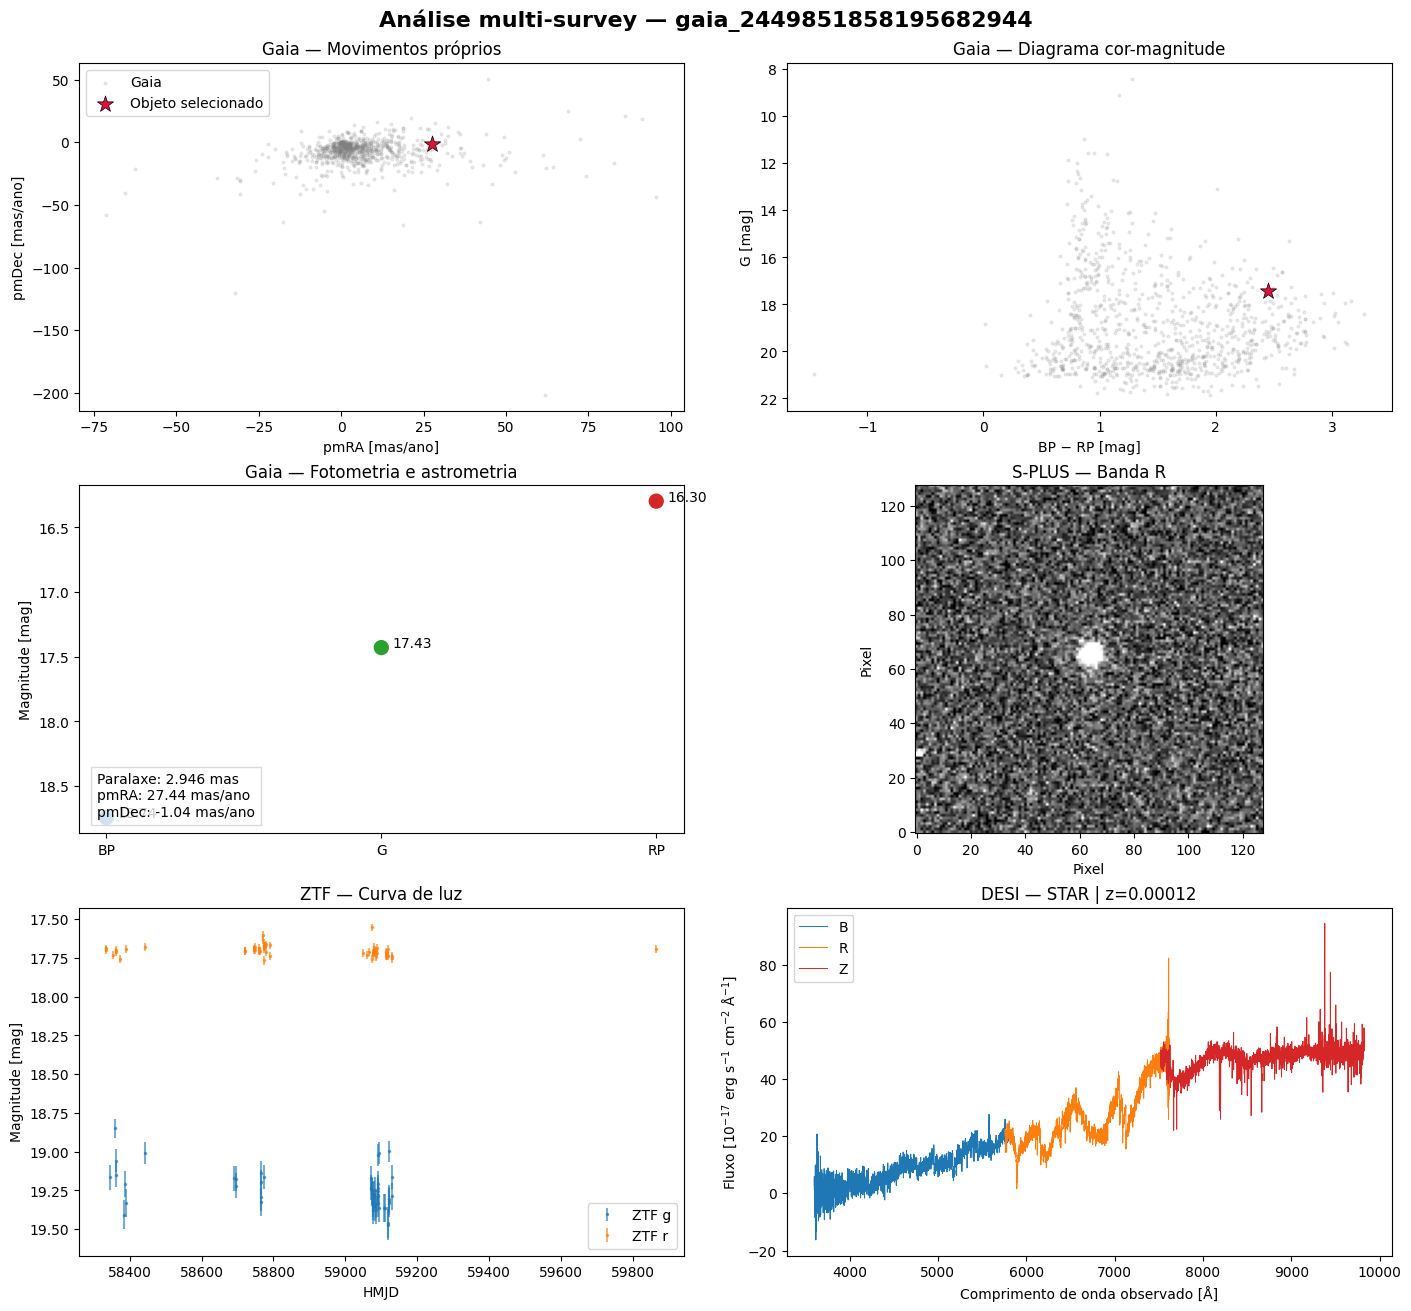

In [84]:
def plot_object(idx):
    example = dataset.iloc[idx]
    image = example.image
    fig, axes = plt.subplots(
        3, 2, figsize=(14, 13),
        constrained_layout=True
    )

    ax_pm, ax_cmd, ax_gaia, ax_image, ax_ztf, ax_desi = axes.flat

    # ============================================================
    # 1. GAIA — MOVIMENTOS PRÓPRIOS
    # ============================================================

    ax_pm.scatter(
        gaia.pmra, gaia.pmdec,
        s=4, alpha=0.15, color="gray",
        label="Gaia"
    )

    ax_pm.scatter(
        example.pmra, example.pmdec,
        s=150, marker="*", color="crimson",
        edgecolor="black", linewidth=0.5,
        label="Objeto selecionado", zorder=5
    )

    ax_pm.set(
        xlabel="pmRA [mas/ano]",
        ylabel="pmDec [mas/ano]",
        title="Gaia — Movimentos próprios"
    )
    ax_pm.legend()


    # ============================================================
    # 2. GAIA — DIAGRAMA COR-MAGNITUDE
    # ============================================================

    # Gaia — Diagrama cor-magnitude

    gaia_color = gaia.phot_bp_mean_mag - gaia.phot_rp_mean_mag
    example_color = example.phot_bp_mean_mag - example.phot_rp_mean_mag

    ax_cmd.scatter(
        gaia_color, gaia.phot_g_mean_mag,
        s=4, alpha=0.15, color="gray"
    )

    ax_cmd.scatter(
        example_color, example.phot_g_mean_mag,
        s=150, marker="*", color="crimson",
        edgecolor="black", linewidth=0.5,
        zorder=5
    )

    ax_cmd.invert_yaxis()
    ax_cmd.set(
        xlabel="BP − RP [mag]",
        ylabel="G [mag]",
        title="Gaia — Diagrama cor-magnitude"
    )

    # ============================================================
    # 3. GAIA — FOTOMETRIA E ASTROMETRIA
    # ============================================================

    bands = ["BP", "G", "RP"]

    magnitudes = [
        example.phot_bp_mean_mag,
        example.phot_g_mean_mag,
        example.phot_rp_mean_mag
    ]

    ax_gaia.scatter(
        bands, magnitudes,
        s=100,
        c=["tab:blue", "tab:green", "tab:red"]
    )

    for band, mag in zip(bands, magnitudes):
        ax_gaia.annotate(
            f"{mag:.2f}",
            (band, mag),
            xytext=(8, 0),
            textcoords="offset points"
        )

    ax_gaia.invert_yaxis()

    ax_gaia.text(
        0.03, 0.05,
        f"Paralaxe: {example.parallax:.3f} mas\n"
        f"pmRA: {example.pmra:.2f} mas/ano\n"
        f"pmDec: {example.pmdec:.2f} mas/ano",
        transform=ax_gaia.transAxes,
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="lightgray")
    )

    ax_gaia.set(
        title="Gaia — Fotometria e astrometria",
        ylabel="Magnitude [mag]"
    )


    # ============================================================
    # 4. S-PLUS — IMAGEM
    # ============================================================

    lo, hi = np.nanpercentile(image, [5, 99.5])

    ax_image.imshow(
        image,
        origin="lower",
        cmap="gray",
        vmin=lo,
        vmax=hi
    )

    ax_image.set(
        title="S-PLUS — Banda R",
        xlabel="Pixel",
        ylabel="Pixel"
    )


    # ============================================================
    # 5. ZTF — CURVA DE LUZ
    # ============================================================

    filter_names = {1: "g", 2: "r", 3: "i"}

    # Todas as curvas guardadas nesta linha da tabela
    ztf_source = pd.DataFrame(example.ztf_curves)

    for band, rows in ztf_source.groupby("filterid"):

        time = np.concatenate(rows.hmjd.to_numpy())
        mag = np.concatenate(rows.mag.to_numpy())
        err = np.concatenate(rows.magerr.to_numpy())

        valid = (
            np.isfinite(time) &
            np.isfinite(mag) &
            np.isfinite(err) &
            (err > 0)
        )

        ax_ztf.errorbar(
            time[valid], mag[valid],
            yerr=err[valid],
            fmt=".", ms=3, alpha=0.6,
            label=f"ZTF {filter_names.get(band, band)}"
        )

    ax_ztf.invert_yaxis()
    ax_ztf.legend()

    ax_ztf.set(
        title="ZTF — Curva de luz",
        xlabel="HMJD",
        ylabel="Magnitude [mag]"
    )


    # ============================================================
    # 6. DESI — ESPECTRO
    # ============================================================

    spectrum = example.spectrum

    arm_colors = {
        "b": "tab:blue",
        "r": "tab:orange",
        "z": "tab:red"
    }

    for arm, color in arm_colors.items():

        wave = np.asarray(spectrum[f"wave_{arm}"], dtype=float)
        flux = np.asarray(spectrum[f"flux_{arm}"], dtype=float)
        ivar = np.asarray(spectrum[f"ivar_{arm}"], dtype=float)

        valid = (
            np.isfinite(wave) &
            np.isfinite(flux) &
            np.isfinite(ivar) &
            (ivar > 0)
        )

        ax_desi.plot(
            wave[valid], flux[valid],
            lw=0.7,
            color=color,
            label=arm.upper()
        )

    ax_desi.legend()

    ax_desi.set(
        title=f"DESI — {example.spectype} | z={example.z:.5f}",
        xlabel="Comprimento de onda observado [Å]",
        ylabel=r"Fluxo [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$]"
    )


    # ============================================================
    # FINAL
    # ============================================================

    fig.suptitle(
        f"Análise multi-survey — {example.object_id}",
        fontsize=16,
        fontweight="bold"
    )

    plt.show()

plot_object(2)

## Investigue

Execute `plot_object(1)` para a segunda fonte. Compare as curvas por filtro, os espectros e `zwarn`. Para conferir o arquivo usado no bônus: `pd.read_pickle(dataset_path).head()`.